In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import nibabel as nib
import math

import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs



from cornucopia import ArrayCoilTransform
from cornucopia.utils.py import meshgrid_ij


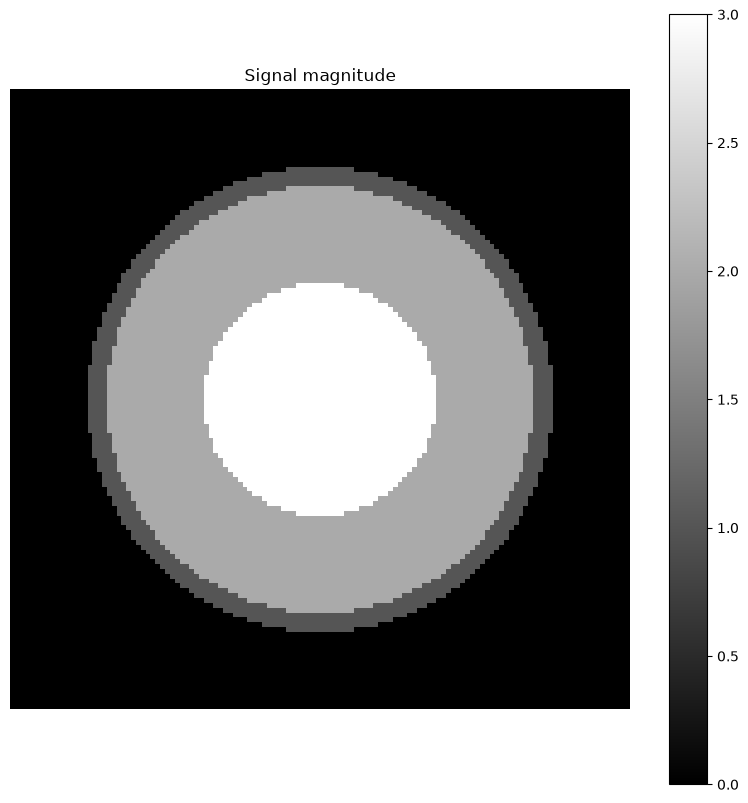

In [2]:
shape = [128, 128]
radius = torch.stack(meshgrid_ij(*[torch.arange(s).float() for s in shape]), -1)
radius -= (torch.as_tensor(shape).float() - 1) / 2
radius = radius.square().sum(-1).sqrt()

mag = torch.zeros_like(radius, dtype=torch.float32)
mag[radius < 48] = 1
mag[radius < 44] = 2
mag[radius < 24] = 3

plt.figure(figsize=(10, 10))
plt.imshow(mag, cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Signal magnitude')
plt.colorbar()
plt.show()

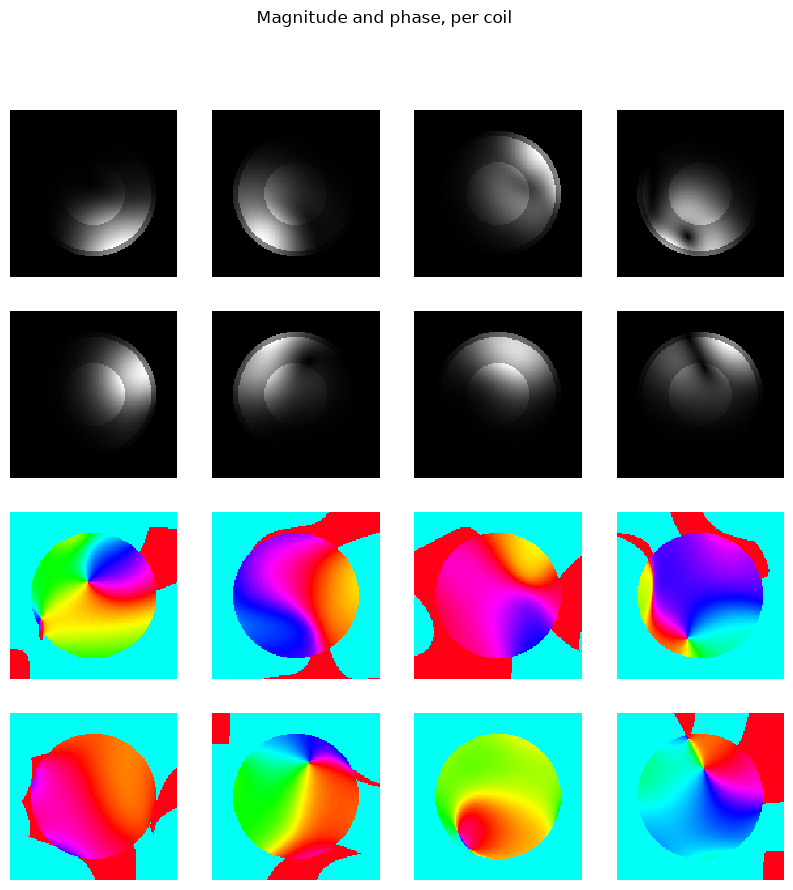

In [5]:
trf = ArrayCoilTransform(ncoils=8)
coils = trf(mag[None])

plt.figure(figsize=(10, 10))
for k in range(len(coils)):
    plt.subplot(4, 4, k+1)
    plt.imshow(coils[k].abs(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.subplot(4, 4, 8+k+1)
    plt.imshow(coils[k].angle(), cmap='hsv', interpolation='nearest',
               vmin=-math.pi, vmax=math.pi)
    plt.axis('off')
plt.suptitle('Magnitude and phase, per coil')
plt.show()

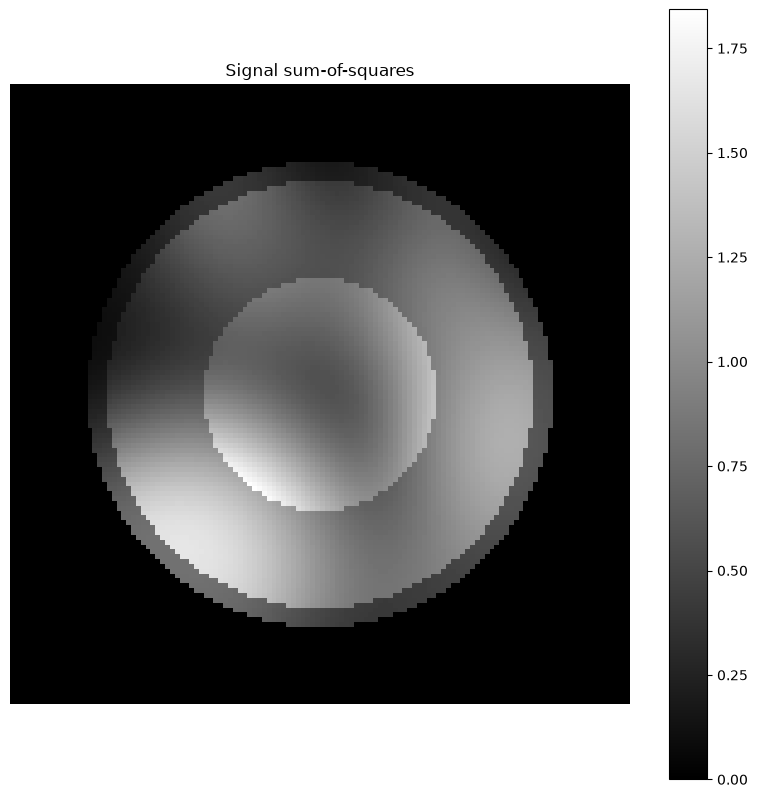

In [14]:
trf = ArrayCoilTransform(returns='sos')
sos = trf(mag[None])[0]

plt.figure(figsize=(10, 10))
plt.imshow(sos, cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Signal sum-of-squares')
plt.colorbar()
plt.show()